
=== XGBoost 기본형 vs 튜닝형 성능 비교 ===


,Model,Accuracy,PASS Recall,FAIL Precision,FAIL Recall,FAIL F1,Macro F1,불량 검출(총 21개),정상 오탐(총 293개)
0,XGBoost (기본형),0.9299,0.9966,0.0000,0.0000,0.0000,0.4818,0개,1개
1,XGBoost1 (튜닝형),0.8439,0.8635,0.2308,0.5714,0.3288,0.6202,12개,40개


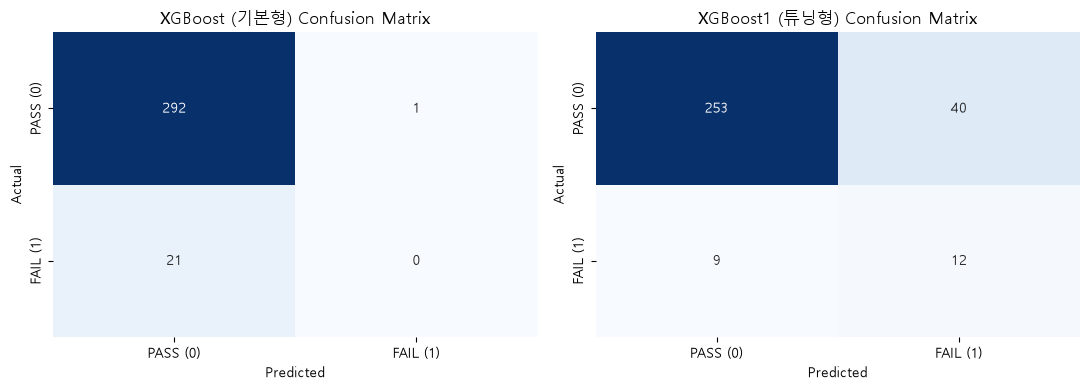

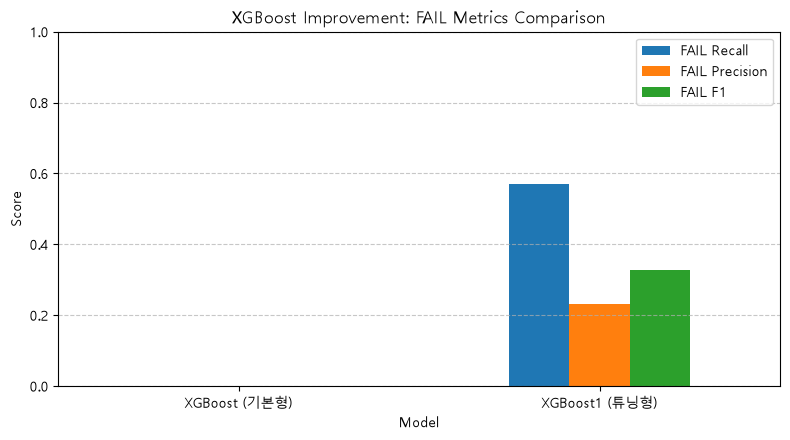

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# === Windows 한글 폰트 설정 (추가) ===
plt.rc("font", family="Malgun Gothic")
plt.rc("axes", unicode_minus=False)

# 1. results 폴더 경로 설정 (comparison code 폴더에서 상위 2단계 위로 이동)
current_dir = Path.cwd()

# notebooks/comparison code 기준 상위 폴더(SECOM_Project/results) 탐색
# 현재 폴더부터 상위로 올라가며 results 폴더 탐색
results_dir = next(p / "results" for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir())

file_targets = {
    "XGBoost (기본형)": results_dir / "06XGBoost.csv",
    "XGBoost1 (튜닝형)": results_dir / "06XGBoost1.csv",
}

# 2. 지표 계산 및 혼동행렬 저장
metrics_list = []
cms = {}

for label, file_path in file_targets.items():
    if not file_path.exists():
        raise FileNotFoundError(
            f"'{file_path.name}' 파일을 찾을 수 없습니다.\n"
            f"실제 탐색 경로: {file_path.resolve()}\n"
            f"05_XGBoost 노트북에서 저장이 완료되었는지 확인하세요."
        )

    df = pd.read_csv(file_path)
    y_true = df["y_true"]
    y_pred = df["y_pred"]

    acc = accuracy_score(y_true, y_pred)
    pass_rec = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    fail_prec = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    fail_rec = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    fail_f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    # 실제 불량(21개) 검출 수 및 정상(293개) 오탐 수 계산
    detected_fail = ((y_true == 1) & (y_pred == 1)).sum()
    false_alarm = ((y_true == 0) & (y_pred == 1)).sum()

    metrics_list.append({
        "Model": label,
        "Accuracy": acc,
        "PASS Recall": pass_rec,
        "FAIL Precision": fail_prec,
        "FAIL Recall": fail_rec,
        "FAIL F1": fail_f1,
        "Macro F1": macro_f1,
        "불량 검출(총 21개)": f"{detected_fail}개",
        "정상 오탐(총 293개)": f"{false_alarm}개",
    })

    cms[label] = confusion_matrix(y_true, y_pred, labels=[0, 1])

# 3. 성능 비교표 출력
comp_df = pd.DataFrame(metrics_list)
print("\n=== XGBoost 기본형 vs 튜닝형 성능 비교 ===")
display(comp_df.style.format({
    "Accuracy": "{:.4f}",
    "PASS Recall": "{:.4f}",
    "FAIL Precision": "{:.4f}",
    "FAIL Recall": "{:.4f}",
    "FAIL F1": "{:.4f}",
    "Macro F1": "{:.4f}",
}))

# 4. 혼동행렬(Confusion Matrix) 좌우 비교 시각화
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, cm) in zip(axes, cms.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["PASS (0)", "FAIL (1)"],
        yticklabels=["PASS (0)", "FAIL (1)"],
        ax=ax,
    )
    ax.set_title(f"{label} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

# 5. 핵심 불량 지표(Recall, Precision, F1) 비교 막대그래프
plot_df = comp_df.set_index("Model")[["FAIL Recall", "FAIL Precision", "FAIL F1"]]
plot_df.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["#1f77b4", "#ff7f0e", "#2ca02c"])
plt.title("XGBoost Improvement: FAIL Metrics Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()